In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import ast

In [2]:
lake = 'zug'
folder_path = rf"/storage/alplakes_test/{lake}_100m_2025"
input_folder = os.path.join(folder_path, "outputs_swirl", "eddy_catalogues_final")

In [3]:
df_lvl2 = pd.read_csv(os.path.join(input_folder, "lvl2.csv"))
df_lvl2 = df_lvl2.set_index('id', drop=False)

In [4]:
def to_array(x):
    if isinstance(x, str):
        return np.array(ast.literal_eval(x))
    return np.array(x)

In [5]:
df_lvl2['dates(t)'] = df_lvl2['dates(t)'].apply(lambda s: pd.to_datetime(ast.literal_eval(s)))

In [6]:
df_lvl2["first_date"] = df_lvl2["dates(t)"].apply(lambda dates: dates[0])
df_lvl2["last_date"] = df_lvl2["dates(t)"].apply(lambda dates: dates[-1])

In [7]:
df_lvl2['volume(t)_[m3]'] = df_lvl2['volume(t)_[m3]'].apply(lambda s: to_array(s))
df_lvl2['depth_min(t)_[m]'] = df_lvl2['depth_min(t)_[m]'].apply(lambda s: to_array(s))
df_lvl2['depth_max(t)_[m]'] = df_lvl2['depth_max(t)_[m]'].apply(lambda s: to_array(s))

In [8]:
df_lvl2['volume_max'] = df_lvl2['volume(t)_[m3]'].apply(lambda volumes: np.max(volumes))
df_lvl2['volume_mean'] = df_lvl2['volume(t)_[m3]'].apply(lambda volumes: np.mean(volumes))

In [9]:
df_lvl2['height'] = df_lvl2['depth_max(t)_[m]'] - df_lvl2['depth_min(t)_[m]']
df_lvl2['height_mean'] = df_lvl2['height'].apply(lambda heights: np.mean(heights))

In [43]:
def get_thickness(target_depth, df_depths):
    target_depths = np.asarray(target_depth)
    depth_values = df_depths["depth_[m]"].to_numpy()
    thickness_values = df_depths["thickness_[m]"].to_numpy()

    positions = np.abs(
        depth_values[:, None] - target_depths.reshape(-1)
    ).argmin(axis=0)
    result = thickness_values[positions].reshape(target_depths.shape)

    return result.item() if target_depths.ndim == 0 else result

In [ ]:
depths = pd.read_csv(os.path.join(folder_path, "grid", "depths.csv"))

In [55]:
df_lvl2['height'] = (df_lvl2['depth_max(t)_[m]'] 
                     - df_lvl2['depth_min(t)_[m]'] 
                     + df_lvl2['depth_max(t)_[m]'].apply(lambda d: -1*get_thickness(d, depths)) / 2
                     + df_lvl2['depth_min(t)_[m]'].apply(lambda d: -1*get_thickness(d, depths)) / 2)

In [10]:
df_lvl2['surface'] = df_lvl2['volume(t)_[m3]'] / df_lvl2['height']
df_lvl2['surface_mean'] = df_lvl2['surface'].apply(lambda surfaces: np.mean(surfaces))

In [11]:
def set_default_figure_setting():
    plt.rcParams.update({
        "figure.figsize": (10, 2),
        "font.family": "serif",
        "font.serif": ["DejaVu Serif"],
        "axes.grid": False,
        "axes.edgecolor": "#8B8B8B",
        "legend.edgecolor": "#8B8B8B",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.minor.visible": False,
        "ytick.minor.visible": False,
    })

set_default_figure_setting()

In [12]:
cpalette = sns.color_palette('colorblind')
cpalette

[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [13]:
seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
seasons_dates = [slice('2025-03-01', '2025-06-01'), slice('2025-06-01', '2025-09-01'), slice('2025-09-01', '2026-01-01'), slice('2026-01-01', '2026-03-01')]
seasons_colors = [cpalette[2], cpalette[8], cpalette[1], cpalette[0]]

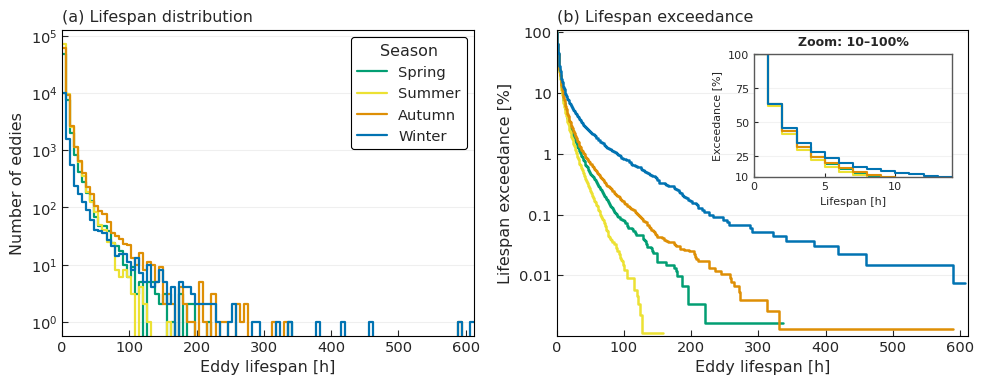

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FixedLocator, FuncFormatter

figure_idx = range(4)
bin_width = 6  # hours

# Collect valid lifespans for each season
seasonal_lifespans = {}

for season_idx in figure_idx:
    start = seasons_dates[season_idx].start
    stop = seasons_dates[season_idx].stop

    seasonal_df = df_lvl2[
        (df_lvl2["last_date"] >= start)
        & (df_lvl2["first_date"] < stop)
    ].copy()

    lifespan = seasonal_df["lifespan_[h]"].to_numpy(dtype=float)
    lifespan = lifespan[np.isfinite(lifespan) & (lifespan > 0)]

    if lifespan.size:
        seasonal_lifespans[season_idx] = lifespan

if not seasonal_lifespans:
    raise ValueError("No valid positive lifespans in the selected seasons.")

# Shared histogram bins
max_lifespan = max(x.max() for x in seasonal_lifespans.values())
bins = np.arange(
    0,
    (np.floor(max_lifespan / bin_width) + 1) * bin_width + 1,
    bin_width
)

# Calculate exceedance curves and zoom limits
seasonal_survival = {}
zoom_end = []

for season_idx, lifespan in seasonal_lifespans.items():
    durations, counts = np.unique(lifespan, return_counts=True)
    survival = np.cumsum(counts[::-1])[::-1] / lifespan.size * 100

    seasonal_survival[season_idx] = (
        np.r_[0, durations],
        np.r_[100, survival]
    )

    below_10 = np.flatnonzero(survival < 10)
    zoom_end.append(
        durations[below_10[0]] if below_10.size else durations[-1]
    )

zoom_xmax = max(zoom_end)

with sns.axes_style("whitegrid"), sns.plotting_context("paper", font_scale=1.2):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # Inset on the right panel
    ax_zoom = axes[1].inset_axes(
        [0.48, 0.52, 0.48, 0.40],
        zorder=5
    )
    ax_zoom.set_facecolor("white")

    for season_idx, lifespan in seasonal_lifespans.items():
        color = seasons_colors[season_idx]
        label = seasons[season_idx].capitalize()
        durations, survival = seasonal_survival[season_idx]

        # Histogram
        sns.histplot(
            x=lifespan,
            bins=bins,
            element="step",
            fill=False,
            color=color,
            linewidth=1.6,
            label=label,
            ax=axes[0]
        )

        # Main exceedance curve
        axes[1].step(
            durations,
            survival,
            where="pre",
            color=color,
            linewidth=1.8
        )

        # Zoomed exceedance curve
        ax_zoom.step(
            durations,
            survival,
            where="pre",
            color=color,
            linewidth=1.5
        )

    axes[0].set(
        yscale="log",
        xlabel="Eddy lifespan [h]",
        ylabel="Number of eddies"
    )
    axes[0].set_title("(a) Lifespan distribution", loc="left")

    min_percentage = min(
        100 / x.size for x in seasonal_lifespans.values()
    )

    axes[1].set(
        yscale="log",
        ylim=(min_percentage * 0.9, 110),
        xlabel="Eddy lifespan [h]",
        ylabel="Lifespan exceedance [%]"
    )
    axes[1].yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:g}")
    )
    axes[1].set_title("(b) Lifespan exceedance", loc="left")

    for ax in axes:
        ax.set_xlim(0, bins[-1])
        ax.grid(axis="x", visible=False)
        ax.grid(axis="y", which="major", alpha=0.3)
        ax.set_axisbelow(True)

        ax.tick_params(
            axis="both",
            which="major",
            direction="in",
            bottom=True,
            top=False,
            left=True,
            right=False,
            length=4,
            width=0.8
        )

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("black")
            spine.set_linewidth(0.8)

    # Legend on the left panel
    legend = axes[0].legend(
        title="Season",
        loc="upper right",
        frameon=True
    )
    legend.get_frame().set_edgecolor("black")
    legend.get_frame().set_alpha(1)

    # Format the inset after plotting all seasons
    ax_zoom.set(
        xlim=(0, zoom_xmax),
        ylim=(10, 100),
        xlabel="Lifespan [h]",
        ylabel="Exceedance [%]"
    )
    ax_zoom.set_title("Zoom: 10–100%", fontsize=9, fontweight="bold")
    ax_zoom.yaxis.set_major_locator(
        FixedLocator([10, 25, 50, 75, 100])
    )
    ax_zoom.yaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:g}")
    )
    ax_zoom.tick_params(
        axis="both",
        which="both",
        direction="in",
        bottom=True,
        left=True,
        length=3,
        width=0.8,
        labelsize=8
    )
    ax_zoom.xaxis.label.set_size(8)
    ax_zoom.yaxis.label.set_size(8)
    ax_zoom.grid(axis="x", visible=False)
    ax_zoom.grid(axis="y", alpha=0.25)
    ax_zoom.set_axisbelow(True)

    for spine in ax_zoom.spines.values():
        spine.set_visible(True)
        spine.set_color("0.35")
        spine.set_linewidth(1)


    fig.tight_layout()
    plt.show()

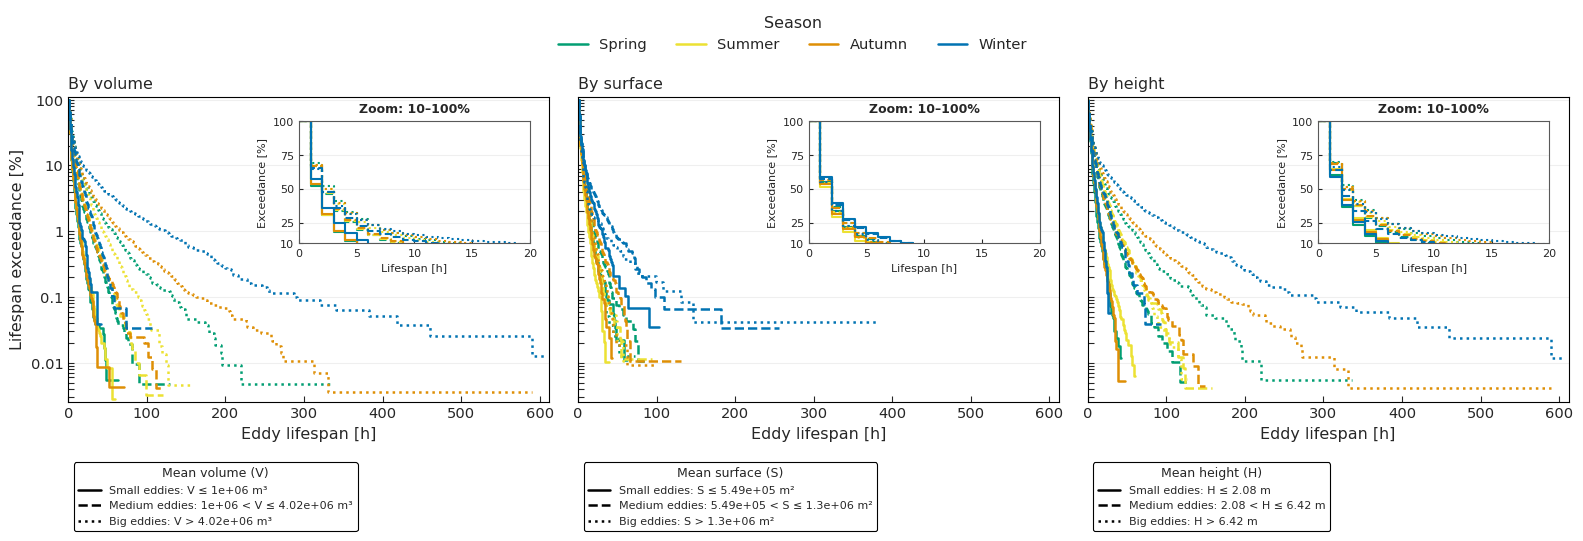

Small eddies  Medium eddies  Big eddies
Panel      Season                                         
By volume  Spring         17966          20971       21233
           Summer         35472          30603       21891
           Autumn         23053          24575       28109
           Winter          2529           2937        7864
By surface Spring          8909           9242        7849
           Summer          9814           8656        9261
           Autumn          8536           9247       10649
           Winter          2889           3008        2389
By height  Spring         16679          19672       18563
           Summer         31862          24369       17415
           Autumn         18660          22335       24566
           Winter          1723           2592        8418

In [81]:
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter

# Each metric uses its own terciles, shared across all seasons.
# Set thresholds to two fixed values (in the specified units) if preferred.
panel_settings = [
    dict(title="By volume", column="volume_mean", symbol="V", unit="m³", thresholds=None),
    dict(title="By surface", column="surface_mean", symbol="S", unit="m²", thresholds=None),
    dict(title="By height", column="height_mean", symbol="H", unit="m", thresholds=None),
]
category_names = ["Small eddies", "Medium eddies", "Big eddies"]
category_styles = ["-", "--", ":"]
period_mask = (
    (df_lvl2["last_date"] >= min(period.start for period in seasons_dates))
    & (df_lvl2["first_date"] < max(period.stop for period in seasons_dates))
)
panel_results = []
season_size_counts = {}

for setting in panel_settings:
    column = setting["column"]
    metric_df = df_lvl2.loc[period_mask, [column, "lifespan_[h]", "first_date", "last_date"]].copy()
    metric_df = metric_df.loc[
        np.isfinite(metric_df[column]) & (metric_df[column] > 0)
        & np.isfinite(metric_df["lifespan_[h]"]) & (metric_df["lifespan_[h]"] > 0)
    ]
    if metric_df.empty:
        raise ValueError(f"No valid {column} values and positive lifespans in the selected period.")
    thresholds = (metric_df[column].quantile([1 / 3, 2 / 3]).to_numpy()
                  if setting["thresholds"] is None else np.asarray(setting["thresholds"], dtype=float))
    if thresholds.shape != (2,) or not np.isfinite(thresholds).all() or thresholds[0] > thresholds[1]:
        raise ValueError(f"Invalid thresholds for {column}: expected two ordered finite values.")
    lower, upper = thresholds
    masks = [metric_df[column] <= lower,
             (metric_df[column] > lower) & (metric_df[column] <= upper),
             metric_df[column] > upper]
    curves, zoom_end = [], []
    group_counts = pd.DataFrame(0, index=seasons, columns=category_names)
    for season_idx, (season, period) in enumerate(zip(seasons, seasons_dates)):
        # Use full lifespans for eddies overlapping each season, as above.
        season_mask = ((metric_df["last_date"] >= period.start)
                       & (metric_df["first_date"] < period.stop))
        for category_idx, mask in enumerate(masks):
            lifespan = metric_df.loc[season_mask & mask, "lifespan_[h]"].to_numpy(dtype=float)
            group_counts.loc[season, category_names[category_idx]] = lifespan.size
            if not lifespan.size:
                continue
            durations, counts = np.unique(lifespan, return_counts=True)
            survival = np.cumsum(counts[::-1])[::-1] / lifespan.size * 100
            curves.append((season_idx, category_idx, np.r_[0, durations],
                           np.r_[100, survival], lifespan.size))
            below_10 = np.flatnonzero(survival < 10)
            zoom_end.append(durations[below_10[0]] if below_10.size else durations[-1])
    if not curves:
        raise ValueError(f"No valid season–size groups for {column}.")
    panel_results.append(dict(setting=setting, thresholds=thresholds, curves=curves,
                              zoom_xmax=max(zoom_end)))
    season_size_counts[setting["title"]] = group_counts

# Shared axes make the three panels directly comparable.
all_curves = [curve for result in panel_results for curve in result["curves"]]
bin_width = 6  # hours
lifespan_xmax = (np.floor(max(curve[2][-1] for curve in all_curves) / bin_width) + 1) * bin_width
min_percentage = min(100 / curve[4] for curve in all_curves)
zoom_xmax = max(result["zoom_xmax"] for result in panel_results)

with sns.axes_style("whitegrid"), sns.plotting_context("paper", font_scale=1.2):
    fig_size, axes_size = plt.subplots(1, 3, figsize=(16, 5.7), sharex=True, sharey=True)
    for ax, result in zip(axes_size, panel_results):
        setting = result["setting"]
        ax_zoom = ax.inset_axes([0.48, 0.52, 0.48, 0.40], zorder=5)
        ax_zoom.set_facecolor("white")
        for season_idx, category_idx, durations, survival, count in result["curves"]:
            for target, width in [(ax, 1.8), (ax_zoom, 1.5)]:
                target.step(durations, survival, where="pre", color=seasons_colors[season_idx],
                            linestyle=category_styles[category_idx], linewidth=width)
        ax.set(xlim=(0, lifespan_xmax), yscale="log", ylim=(min_percentage * 0.9, 110),
               xlabel="Eddy lifespan [h]")
        ax.set_title(setting["title"], loc="left")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))

        lower, upper = result["thresholds"]
        symbol, unit = setting["symbol"], setting["unit"]
        bounds = [f"{symbol} ≤ {lower:.3g} {unit}",
                  f"{lower:.3g} < {symbol} ≤ {upper:.3g} {unit}",
                  f"{symbol} > {upper:.3g} {unit}"]
        handles = [Line2D([0], [0], color="black", linestyle=style, linewidth=1.8,
                          label=f"{name}: {bound}")
                   for name, style, bound in zip(category_names, category_styles, bounds)]
        legend = ax.legend(handles=handles, title=f"Mean {setting['title'][3:]} ({symbol})",
                           loc="upper left", bbox_to_anchor=(0, -0.18),
                           frameon=True, fontsize=8, title_fontsize=9)
        legend.get_frame().set_edgecolor("black")
        legend.get_frame().set_alpha(1)

        ax_zoom.set(xlim=(0, zoom_xmax), ylim=(10, 100),
                    xlabel="Lifespan [h]", ylabel="Exceedance [%]")
        ax_zoom.set_title("Zoom: 10–100%", fontsize=9, fontweight="bold")
        ax_zoom.yaxis.set_major_locator(FixedLocator([10, 25, 50, 75, 100]))
        ax_zoom.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
        ax_zoom.xaxis.label.set_size(8)
        ax_zoom.yaxis.label.set_size(8)
        for target, tick_size, line_color in [(ax, 4, "black"), (ax_zoom, 3, "0.35")]:
            target.grid(axis="x", visible=False)
            target.grid(axis="y", which="major", alpha=0.3)
            target.set_axisbelow(True)
            target.tick_params(axis="both", which="both", direction="in", bottom=True,
                               top=False, left=True, right=False, length=tick_size, width=0.8)
            for spine in target.spines.values():
                spine.set_visible(True)
                spine.set_color(line_color)
                spine.set_linewidth(0.8)
        ax_zoom.tick_params(labelsize=8)

    axes_size[0].set_ylabel("Lifespan exceedance [%]")
    present_seasons = {curve[0] for curve in all_curves}
    season_handles = [Line2D([0], [0], color=seasons_colors[i], linewidth=1.8, label=season)
                      for i, season in enumerate(seasons) if i in present_seasons]
    fig_size.legend(handles=season_handles, title="Season", loc="upper center",
                    bbox_to_anchor=(0.5, 1), ncol=len(season_handles), frameon=False)
    fig_size.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()

# Number of eddies behind each season–size curve, grouped by panel.
pd.concat(season_size_counts, names=["Panel", "Season"])


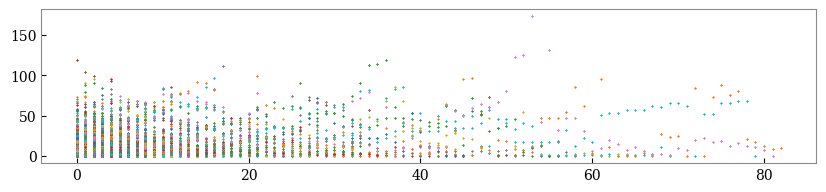

In [19]:
for idx in range(720):
    plt.plot(df_lvl2[df_lvl2['lifespan_[h]'] > 2]['height'].iloc[idx], ls='', marker='x', ms=1)

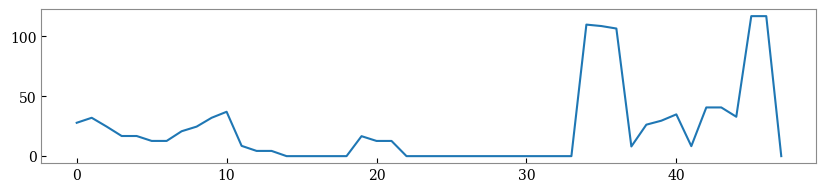

In [77]:
plt.plot(df_lvl2['height'].iloc[6])

### Probability of surviving one more hour by current height

For each recorded eddy observation, estimate $P(T_{end} \geq t+1\,h \mid H(t))$ as the fraction of observations in a height bin whose track lasts at least one more hour. Height is the **current vertical extent**, taken directly from the existing `df_lvl2["height"]` arrays. Zero-height detections are retained in the first bin. Each observation is assigned to one of the existing `seasons_dates` intervals by its current timestamp (start inclusive, stop exclusive). Follow-up may cross the season boundary. Longer tracks contribute more observations. The four curves use the existing seasonal colours.

Observations without a full hour of follow-up before the catalogue end are excluded (right censoring). The follow-up boundary is fixed at `2026-03-01 00:00:00`. Tracking can bridge missing detections, so continuation is defined by track end, including those gaps, rather than requiring detection exactly one hour later. Disappearance means the end of a tracked identity, not necessarily physical dissipation. The level-2 catalogue excludes unlinked single detections, so these probabilities apply to catalogued tracks only.

The shaded 95% interval comes from resampling entire eddy tracks, preserving dependence between observations of the same eddy. Shared height bins are 1 m wide below 10 m, 2 m from 10–20 m, 5 m from 20–50 m, and 10 m above 50 m. Bin edges and bootstrap settings can be changed below. Bins with fewer than `min_tracks_per_bin` contributing tracks remain in the table but are omitted from the plot.

The second panel zooms into 0–20 m, with a vertical range fitted to the displayed uncertainty bands so small-height differences are easier to see. Adjust `height_zoom_max` to change the zoom.


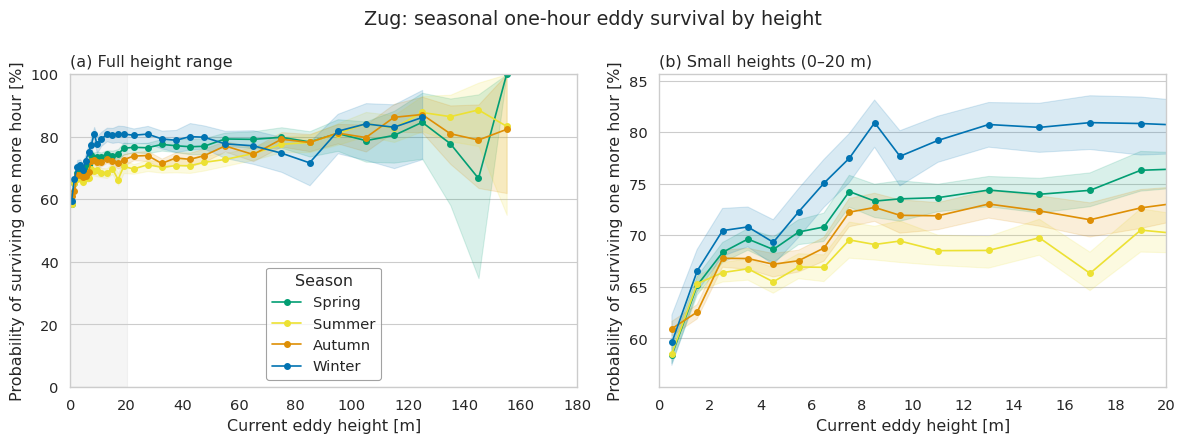

height_lower_m  height_upper_m  n_observations  n_tracks  \
Season Height bin                                                             
Spring 0                      0.0             1.0           12288      7267   
       1                      1.0             2.0           14656      8916   
       2                      2.0             3.0           10298      6790   
       3                      3.0             4.0            8329      5697   
       4                      4.0             5.0            6138      4589   
...                           ...             ...             ...       ...   
Winter 29                   130.0           140.0               9         7   
       30                   140.0           150.0               0         0   
       31                   150.0           160.0               0         0   
       32                   160.0           170.0               0         0   
       33                   170.0           180.0               0         0   

                   n_survived  survival_probability  ci95_lower  ci95_upper  
Season Height bin                                                            
Spring 0                 7174              0.583822    0.575506    0.592319  
       1                 9548              0.651474    0.641942    0.660046  
       2                 7038              0.683434    0.673495    0.692936  
       3                 5800              0.696362    0.685465    0.706466  
       4                 4212              0.686217    0.673646    0.698401  
...                       ...                   ...         ...         ...  
Winter 29                   9              1.000000    1.000000    1.000000  
       30                   0                   NaN         NaN         NaN  
       31                   0                   NaN         NaN         NaN  
       32                   0                   NaN         NaN         NaN  
       33                   0                   NaN         NaN         NaN  

[136 rows x 8 columns]

In [59]:
# One-hour survival conditional on the eddy's height at the current observation.
survival_horizon = pd.Timedelta(hours=1)
# Shared bins: 1 m below 10 m, 2 m from 10–20 m, 5 m from 20–50 m,
# then 10 m for larger heights.
min_tracks_per_bin = 10
n_bootstrap = 500
rng = np.random.default_rng(42)

catalogue_end = pd.Timestamp("2026-03-01")

observation_frames = []
for track_idx, (_, row) in enumerate(df_lvl2.iterrows()):
    dates = pd.DatetimeIndex(row["dates(t)"])
    height = np.asarray(row["height"], dtype=float)
    if len(dates) != len(height):
        raise ValueError(f"Date/height array lengths differ for eddy {row['id']}.")
    if dates.hasnans or not dates.is_monotonic_increasing or dates.has_duplicates:
        raise ValueError(f"Invalid or unordered timestamps for eddy {row['id']}.")
    if not len(dates):
        continue
    eligible = np.isfinite(height) & (height >= 0) & (dates + survival_horizon <= catalogue_end)
    observation_frames.append(pd.DataFrame({
        "track_idx": track_idx,
        "date": dates[eligible],
        "height_m": height[eligible],
        "survived": np.asarray(dates + survival_horizon <= dates[-1])[eligible],
    }))

if not observation_frames:
    raise ValueError("No eddy tracks available for the survival estimate.")
survival_observations = pd.concat(observation_frames, ignore_index=True)
if survival_observations.empty:
    raise ValueError("No valid heights with one hour of follow-up.")

height_max = survival_observations["height_m"].max()
height_edges = np.unique(np.r_[
    np.arange(0, 11, 1), np.arange(12, 21, 2), np.arange(25, 51, 5),
    np.arange(60, max(60, np.floor(height_max / 10) * 10 + 10) + 1, 10),
])
# Left-closed bins [lower, upper); the final edge exceeds the largest height.
n_height_bins = len(height_edges) - 1
survival_observations["height_bin"] = np.searchsorted(
    height_edges, survival_observations["height_m"], side="right"
) - 1

season_results = {}
for season, period in zip(seasons, seasons_dates):
    seasonal_observations = survival_observations.loc[
        (survival_observations["date"] >= pd.Timestamp(period.start))
        & (survival_observations["date"] < pd.Timestamp(period.stop))
    ]
    # Assign by the current timestamp; follow-up may cross a season boundary.
    if seasonal_observations.empty:
        season_results[season] = pd.DataFrame({
            "height_lower_m": height_edges[:-1], "height_upper_m": height_edges[1:],
            "n_observations": 0, "n_tracks": 0, "n_survived": 0,
            "survival_probability": np.nan, "ci95_lower": np.nan, "ci95_upper": np.nan,
        })
        continue
    # Aggregate within tracks before bootstrapping, so hourly observations are not
    # incorrectly treated as independent samples for the uncertainty interval.
    track_counts = seasonal_observations.groupby(["track_idx", "height_bin"])["survived"].agg(
        observations="size", survivors="sum"
    )
    track_ids = seasonal_observations["track_idx"].unique()
    bin_ids = np.arange(n_height_bins)
    counts = track_counts["observations"].unstack(fill_value=0).reindex(
        index=track_ids, columns=bin_ids, fill_value=0
    ).to_numpy(dtype=float)
    survivors = track_counts["survivors"].unstack(fill_value=0).reindex(
        index=track_ids, columns=bin_ids, fill_value=0
    ).to_numpy(dtype=float)

    n_obs = counts.sum(axis=0)
    n_survivors = survivors.sum(axis=0)
    probability = np.divide(n_survivors, n_obs, out=np.full(n_height_bins, np.nan), where=n_obs > 0)
    bootstrap_probability = np.full((n_bootstrap, n_height_bins), np.nan)
    for replicate in range(n_bootstrap):
        selected = rng.integers(0, len(track_ids), size=len(track_ids))
        denominator = counts[selected].sum(axis=0)
        bootstrap_probability[replicate] = np.divide(
            survivors[selected].sum(axis=0), denominator,
            out=np.full(n_height_bins, np.nan), where=denominator > 0,
        )

    interval = np.full((2, n_height_bins), np.nan)
    for bin_idx in np.flatnonzero(n_obs > 0):
        values = bootstrap_probability[:, bin_idx]
        interval[:, bin_idx] = np.quantile(values[np.isfinite(values)], [0.025, 0.975])

    season_results[season] = pd.DataFrame({
        "height_lower_m": height_edges[:-1],
        "height_upper_m": height_edges[1:],
        "n_observations": n_obs.astype(int),
        "n_tracks": (counts > 0).sum(axis=0),
        "n_survived": n_survivors.astype(int),
        "survival_probability": probability,
        "ci95_lower": interval[0],
        "ci95_upper": interval[1],
    })

survival_by_height = pd.concat(season_results, names=["Season", "Height bin"])
centres = (height_edges[:-1] + height_edges[1:]) / 2
# Separate panel makes the finely spaced bins at small heights readable.
height_zoom_max = 20.0  # metres
with sns.axes_style("whitegrid"), sns.plotting_context("paper", font_scale=1.2):
    fig_survival_height, axes_height = plt.subplots(1, 2, figsize=(12, 4.5))
    zoom_bounds = []
    for season, color in zip(seasons, seasons_colors):
        result = season_results[season]
        plot_mask = result["n_tracks"].to_numpy() >= min_tracks_per_bin
        probability_pct = np.where(plot_mask, result["survival_probability"] * 100, np.nan)
        lower_pct = np.where(plot_mask, result["ci95_lower"] * 100, np.nan)
        upper_pct = np.where(plot_mask, result["ci95_upper"] * 100, np.nan)
        for ax in axes_height:
            ax.plot(centres, probability_pct, marker="o", markersize=4,
                    color=color, label=season)
            ax.fill_between(centres, lower_pct, upper_pct, color=color, alpha=0.15)
        zoom_mask = centres <= height_zoom_max
        zoom_bounds.extend(lower_pct[zoom_mask & np.isfinite(lower_pct)])
        zoom_bounds.extend(upper_pct[zoom_mask & np.isfinite(upper_pct)])

    axes_height[0].set(xlim=(0, height_edges[-1]), ylim=(0, 100),
                       ylabel="Probability of surviving one more hour [%]")
    axes_height[0].set_title("(a) Full height range", loc="left")
    axes_height[0].axvspan(0, height_zoom_max, color="0.5", alpha=0.08, zorder=0)
    axes_height[1].set(xlim=(0, height_zoom_max),
                       ylabel="Probability of surviving one more hour [%]")
    axes_height[1].set_title("(b) Small heights (0–20 m)", loc="left")
    axes_height[1].set_xticks(np.arange(0, height_zoom_max + 1, 2))
    # Fit the zoom's y range to the displayed confidence bands.
    if zoom_bounds:
        zoom_lower, zoom_upper = min(zoom_bounds), max(zoom_bounds)
        padding = max(2.0, 0.08 * (zoom_upper - zoom_lower))
        axes_height[1].set_ylim(max(0, zoom_lower - padding), min(100, zoom_upper + padding))
    else:
        axes_height[1].set_ylim(0, 100)
    for ax in axes_height:
        ax.set_xlabel("Current eddy height [m]")
        ax.grid(axis="x", visible=False)
    axes_height[0].legend(title="Season", frameon=True)
    fig_survival_height.suptitle(f"{lake.capitalize()}: seasonal one-hour eddy survival by height")
    fig_survival_height.tight_layout()
    plt.show()

# Probabilities and 95% track-bootstrap intervals are fractions (0–1).
survival_by_height
